# Informe de laboratorio: Análisis exploratorio del catálogo de Netflix y la valoración de usuarios
**Integrantes:** James Francois Lozano Gordillo · Elian Alexis Sandoval Durán  
**Institución:** UNIMINUTO sede Ibagué — Ingeniería de Sistemas · Minería de Datos

**Pregunta de negocio:** ¿Cómo está compuesto y cómo ha crecido el catálogo de Netflix, y qué características del contenido (género, audiencia, duración, antigüedad) se asocian con una mejor valoración de los usuarios?

**Variable objetivo del análisis bivariado:** `user_rating_score` (puntuación de usuarios, 0–100).

**Objetivos:** (1) evaluar la calidad de los datos y documentar decisiones; (2) describir el catálogo (univariado); (3) cruzar las características del contenido con la valoración (bivariado/multivariado); (4) formular y validar hipótesis con pruebas estadísticas.

> Para reproducir: colocar `netflix_titles.csv` y `netflix.csv` en la carpeta `CSV/` junto a este notebook y ejecutar todas las celdas.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import os
os.makedirs('figs', exist_ok=True)
sns.set_theme(style='whitegrid', palette=['#B81D24','#221F1F','#8C8C8C'])
ROJO, NEGRO, GRIS = '#B81D24', '#221F1F', '#8C8C8C'
pd.set_option('display.width', 140)

def guardar(nombre):
    plt.tight_layout(); plt.savefig(f'figs/{nombre}.png', dpi=170); plt.show()

titulos_raw = pd.read_csv('CSV/netflix_titles.csv')
valor_raw = pd.read_csv('CSV/netflix.csv')
print('Catálogo:', titulos_raw.shape, '| Valoraciones:', valor_raw.shape)

Catálogo: (8807, 12) | Valoraciones: (1000, 7)


## 2. Calidad de datos

### 2.1 Valores nulos

In [2]:
def tabla_nulos(df):
    t = pd.DataFrame({'nulos': df.isnull().sum(), '% nulos': (df.isnull().mean()*100).round(2)})
    return t[t.nulos > 0].sort_values('nulos', ascending=False)

print('--- Catálogo (netflix_titles.csv) ---'); display(tabla_nulos(titulos_raw))
print('--- Valoraciones (netflix.csv, crudo) ---'); display(tabla_nulos(valor_raw))

--- Catálogo (netflix_titles.csv) ---


,nulos,% nulos
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


--- Valoraciones (netflix.csv, crudo) ---


,nulos,% nulos
user_rating_score,395,39.5
ratingdescription,59,5.9


### 2.2 Duplicados

In [3]:
print('Catálogo: filas duplicadas =', titulos_raw.duplicated().sum(), '| show_id duplicados =', titulos_raw.show_id.duplicated().sum())
dup = valor_raw.duplicated().sum()
print(f'Valoraciones: filas duplicadas = {dup} ({dup/len(valor_raw)*100:.0f}% del archivo)')
v_unico = valor_raw.drop_duplicates().copy()
print('Promedio de user_rating_score CON duplicados :', round(valor_raw.user_rating_score.mean(), 2))
print('Promedio de user_rating_score SIN duplicados :', round(v_unico.user_rating_score.mean(), 2))
print('\nNulos de score vs. user_rating_size (tras quitar duplicados):')
display(pd.crosstab(v_unico.user_rating_size, v_unico.user_rating_score.isna(), rownames=['user_rating_size'], colnames=['score nulo']))

Catálogo: filas duplicadas = 0 | show_id duplicados = 0
Valoraciones: filas duplicadas = 500 (50% del archivo)
Promedio de user_rating_score CON duplicados : 84.09
Promedio de user_rating_score SIN duplicados : 81.4

Nulos de score vs. user_rating_size (tras quitar duplicados):


score nulo,False,True
user_rating_size,,
80,256,0
81,0,2
82,0,242


### 2.3 Inconsistencias (columnas desplazadas)

In [4]:
validos = ['G','PG','PG-13','R','NC-17','TV-Y','TV-Y7','TV-Y7-FV','TV-G','TV-PG','TV-14','TV-MA','NR','UR']
sospechosos = titulos_raw[~titulos_raw.rating.isin(validos) & titulos_raw.rating.notna()]
display(sospechosos[['title','rating','duration','type']])

# Fechas: espacios al inicio en date_added
con_espacio = titulos_raw.date_added.dropna().str.startswith(' ').sum()
nat_sin_strip = pd.to_datetime(titulos_raw.date_added, errors='coerce').isna().sum()
nat_con_strip = pd.to_datetime(titulos_raw.date_added.str.strip(), errors='coerce', format='mixed').isna().sum()
print(f'date_added con espacio inicial: {con_espacio}')
print(f'Fechas inválidas sin strip: {nat_sin_strip} | con strip: {nat_con_strip}  → se recuperan {nat_sin_strip-nat_con_strip} fechas')

,title,rating,duration,type
5541,Louis C.K. 2017,74 min,NaN,Movie
5794,Louis C.K.: Hilarious,84 min,NaN,Movie
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN,Movie


date_added con espacio inicial: 88
Fechas inválidas sin strip: 98 | con strip: 10  → se recuperan 88 fechas


### 2.4 Limpieza aplicada (misma lógica del pipeline `LimpiadorDatos`)

In [5]:
catalogo = titulos_raw.drop_duplicates().copy()
for c in ['director','cast','country','rating','duration']:
    catalogo[c] = catalogo[c].fillna('Desconocido')
catalogo['date_added'] = pd.to_datetime(catalogo['date_added'].str.strip(), errors='coerce', format='mixed')

mask = ~catalogo.rating.isin(validos + ['Desconocido'])
catalogo.loc[mask, 'duration'] = catalogo.loc[mask, 'rating']
catalogo.loc[mask, 'rating'] = 'Desconocido'

catalogo['durationValue'] = pd.to_numeric(catalogo.duration.str.split(' ').str[0], errors='coerce')
catalogo['added_year'] = catalogo.date_added.dt.year
catalogo['antiguedad_al_agregar'] = catalogo.added_year - catalogo.release_year

valoraciones = v_unico.copy()
val = valoraciones.dropna(subset=['user_rating_score']).copy()
print('Catálogo limpio:', catalogo.shape, '| Valoraciones únicas:', valoraciones.shape, '| con score válido:', len(val))

Catálogo limpio: (8807, 15) | Valoraciones únicas: (500, 7) | con score válido: 256


### 2.5 Outliers (regla del rango intercuartílico, 1.5·IQR)

In [6]:
def outliers_iqr(s, nombre):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    lo, hi = q1 - 1.5*i, q3 + 1.5*i; n = int(((s < lo) | (s > hi)).sum())
    return {'variable': nombre, 'n': len(s), 'límite inf.': round(lo,1), 'límite sup.': round(hi,1),
            'outliers': n, '% outliers': round(n/len(s)*100, 1)}

peliculas = catalogo[catalogo.type == 'Movie']; series = catalogo[catalogo.type == 'TV Show']
tabla_out = pd.DataFrame([
    outliers_iqr(peliculas.durationValue, 'Duración películas (min)'),
    outliers_iqr(series.durationValue, 'Temporadas series'),
    outliers_iqr(catalogo.release_year, 'Año de lanzamiento (catálogo)'),
    outliers_iqr(catalogo.antiguedad_al_agregar, 'Antigüedad al agregar (años)'),
    outliers_iqr(val.user_rating_score, 'Valoración de usuarios'),
])
display(tabla_out)
print('Películas más cortas:'); display(peliculas.nsmallest(3, 'durationValue')[['title','duration']])
print('Películas más largas:'); display(peliculas.nlargest(3, 'durationValue')[['title','duration']])
neg = catalogo[catalogo.antiguedad_al_agregar < 0]
print('Antigüedad negativa:', len(neg), 'títulos →', neg.type.value_counts().to_dict())

,variable,n,límite inf.,límite sup.,outliers,% outliers
0,Duración películas (min),6131,46.5,154.5,450,7.3
1,Temporadas series,2676,-0.5,3.5,259,9.7
2,Año de lanzamiento (catálogo),8807,2004.0,2028.0,719,8.2
3,Antigüedad al agregar (años),8797,-7.5,12.5,972,11.0
4,Valoración de usuarios,256,38.0,126.0,0,0.0


Películas más cortas:


,title,duration
3777,Silent,3 min
2713,Sol Levante,5 min
1484,Cops and Robbers,8 min


Películas más largas:


,title,duration
4253,Black Mirror: Bandersnatch,312 min
717,Headspace: Unwind Your Mind,273 min
2491,The School of Mischief,253 min


Antigüedad negativa: 14 títulos → {'TV Show': 12, 'Movie': 2}


**Decisiones de calidad** (documentadas en el informe): se eliminan 500 duplicados exactos de `netflix.csv`; los nulos de texto del catálogo se conservan como `"Desconocido"` en vez de borrar filas; las 3 filas con `duration` desplazada a `rating` se corrigen; las 88 fechas con espacio inicial se recuperan con `.str.strip()` antes de convertir; los outliers de duración se **conservan** (son valores reales: cortometrajes y especiales) y se analizan con estadísticos robustos (mediana); los nulos de `user_rating_score` **no se imputan**: son estructurales (ver 2.2) y el análisis de valoración usa solo los 256 registros con puntuación.

## 3. Análisis univariado

### 3.1 Tablas descriptivas

In [7]:
print('Variables numéricas del catálogo'); display(catalogo[['release_year','added_year','durationValue','antiguedad_al_agregar']].describe().round(2))
print('Duración por tipo'); display(catalogo.groupby('type').durationValue.describe().round(1))
print('Valoraciones de usuarios'); display(val[['user_rating_score','release_year','rating_level']].describe().round(2))
print('Variables categóricas — tipo y clasificación')
display(pd.DataFrame({'tipo': catalogo.type.value_counts()}).T)
display(catalogo.rating.value_counts().head(8).to_frame('títulos').T)

Variables numéricas del catálogo


,release_year,added_year,durationValue,antiguedad_al_agregar
count,8807.00,8797.00,8807.00,8797.00
mean,2014.18,2018.87,69.85,4.69
std,8.82,1.57,50.81,8.79
min,1925.00,2008.00,1.00,-3.00
25%,2013.00,2018.00,2.00,0.00
50%,2017.00,2019.00,88.00,1.00
75%,2019.00,2020.00,106.00,5.00
max,2021.00,2021.00,312.00,93.00


Duración por tipo


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Movie,6131.0,99.6,28.3,3.0,87.0,98.0,114.0,312.0
TV Show,2676.0,1.8,1.6,1.0,1.0,1.0,2.0,17.0


Valoraciones de usuarios


,user_rating_score,release_year,rating_level
count,256.00,256.00,256.00
mean,81.40,2010.52,74.45
std,12.73,8.80,26.89
min,55.00,1940.00,10.00
25%,71.00,2007.00,60.00
50%,83.50,2015.00,80.00
75%,93.00,2016.00,90.00
max,99.00,2017.00,124.00


Variables categóricas — tipo y clasificación


type,Movie,TV Show
tipo,6131,2676


rating,TV-MA,TV-14,TV-PG,R,PG-13,TV-Y7,TV-Y,PG
títulos,3207,2160,863,799,490,334,307,287


### 3.2 Gráfico 1 — Composición por tipo de contenido

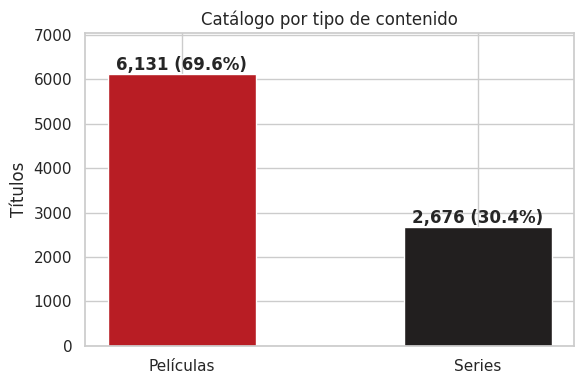

In [8]:
tipo = catalogo.type.value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Películas','Series'], tipo.values, color=[ROJO, NEGRO], width=.5)
for i, v in enumerate(tipo.values): ax.text(i, v+80, f'{v:,} ({v/tipo.sum()*100:.1f}%)', ha='center', fontweight='bold')
ax.set_title('Catálogo por tipo de contenido'); ax.set_ylabel('Títulos'); ax.set_ylim(0, tipo.max()*1.15)
guardar('g1_tipo')

**Interpretación.** Las películas representan cerca del 70% del catálogo y las series cerca del 30%: Netflix ofrece más del doble de películas que de series. Esto importa porque cualquier promedio general del catálogo está dominado por el comportamiento de las películas.

### 3.3 Gráfico 2 — Títulos agregados por año

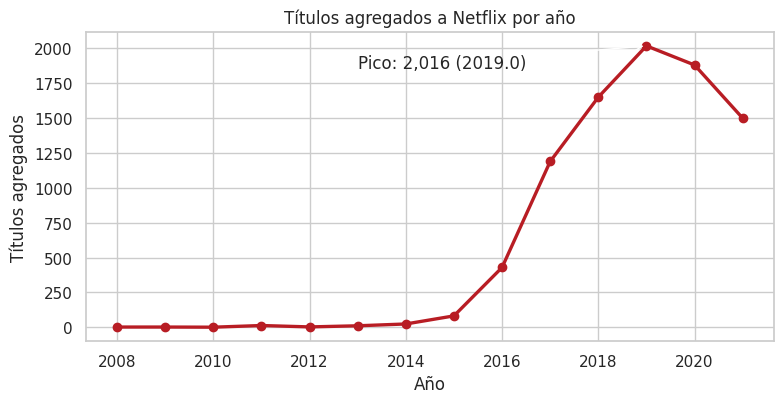

,títulos
added_year,
2014.0,24
2015.0,82
2016.0,429
2017.0,1188
2018.0,1649
2019.0,2016
2020.0,1879
2021.0,1498


In [9]:
por_anio = catalogo.dropna(subset=['date_added']).groupby('added_year').size()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(por_anio.index, por_anio.values, marker='o', color=ROJO, lw=2.4)
pico = por_anio.idxmax(); ax.annotate(f'Pico: {por_anio.max():,} ({pico})', (pico, por_anio.max()), xytext=(pico-6, por_anio.max()*0.92), arrowprops=dict(arrowstyle='->'))
ax.set_title('Títulos agregados a Netflix por año'); ax.set_xlabel('Año'); ax.set_ylabel('Títulos agregados')
guardar('g2_crecimiento'); display(por_anio.tail(8).to_frame('títulos'))

**Interpretación.** El catálogo creció de forma casi imperceptible hasta 2015 y despegó desde 2016, con su máximo en 2019. En 2020 y 2021 las incorporaciones bajan: la plataforma pasó de acumular volumen a un ritmo más moderado.

### 3.4 Gráfico 3 — Principales países y géneros

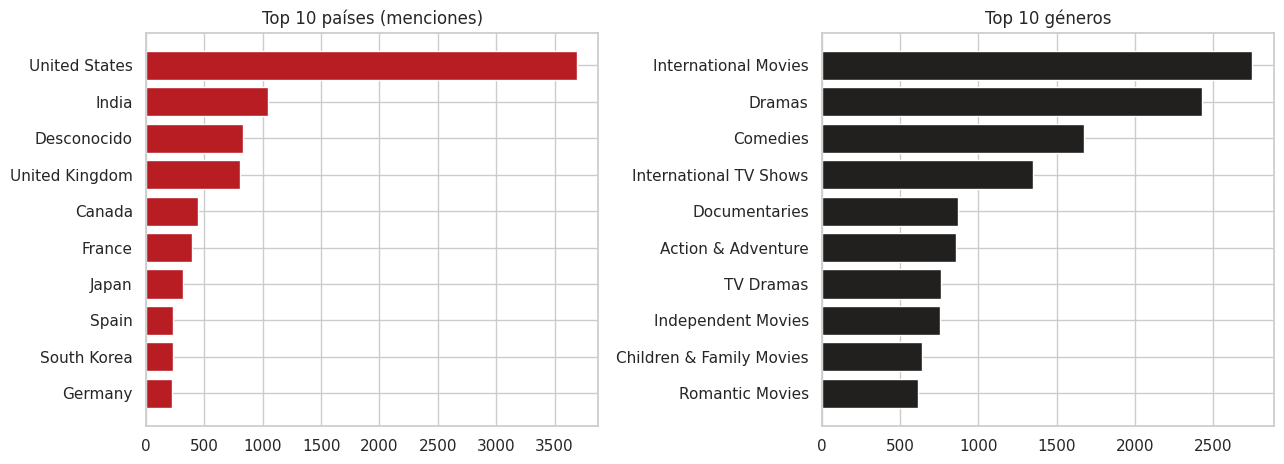

country,United States,India,Desconocido,United Kingdom,Canada,France,Japan,Spain,South Korea,Germany
menciones,3689,1046,831,804,445,393,318,232,231,226


listed_in,International Movies,Dramas,Comedies,International TV Shows,Documentaries,Action & Adventure,TV Dramas,Independent Movies,Children & Family Movies,Romantic Movies
títulos,2752,2427,1674,1351,869,859,763,756,641,616


In [10]:
paises = catalogo.assign(country=catalogo.country.str.split(', ')).explode('country')
paises['country'] = paises.country.str.strip()
generos = catalogo.assign(listed_in=catalogo.listed_in.str.split(', ')).explode('listed_in')
generos['listed_in'] = generos.listed_in.str.strip()
tp = paises.country.value_counts().head(10); tg = generos.listed_in.value_counts().head(10)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].barh(tp.index[::-1], tp.values[::-1], color=ROJO); axs[0].set_title('Top 10 países (menciones)')
axs[1].barh(tg.index[::-1], tg.values[::-1], color=NEGRO); axs[1].set_title('Top 10 géneros')
guardar('g3_paises_generos'); display(tp.to_frame('menciones').T); display(tg.to_frame('títulos').T)

**Interpretación.** Estados Unidos concentra la mayor producción, seguido por India y Reino Unido; "Desconocido" (países no declarados) pesa cerca del 10% y debe leerse con cautela. En géneros dominan *International Movies*, *Dramas* y *Comedies*: el catálogo es amplio y fuertemente internacional.

### 3.5 Gráfico 4 — Duración de las películas (y outliers)

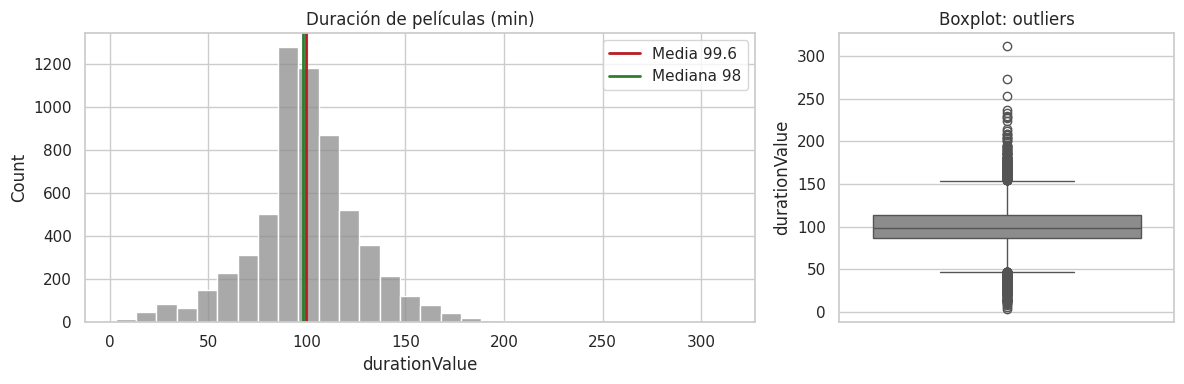

Media: 99.6 | Mediana: 98.0 | Asimetría (skew): 0.2


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios':[2,1]})
dv = peliculas.durationValue.dropna()
sns.histplot(dv, bins=30, color=GRIS, ax=axs[0])
axs[0].axvline(dv.mean(), color=ROJO, lw=2, label=f'Media {dv.mean():.1f}')
axs[0].axvline(dv.median(), color='#2E7D32', lw=2, label=f'Mediana {dv.median():.0f}')
axs[0].set_title('Duración de películas (min)'); axs[0].legend()
sns.boxplot(y=dv, color=GRIS, ax=axs[1]); axs[1].set_title('Boxplot: outliers')
guardar('g4_duracion'); print('Media:', round(dv.mean(),1), '| Mediana:', dv.median(), '| Asimetría (skew):', round(stats.skew(dv),2))

**Interpretación.** La línea roja (media, 99,6) queda apenas a la derecha de la verde (mediana, 98): asimetría positiva leve (≈ 0,2) por la cola de películas muy largas. Una película típica dura unos 98 minutos. El boxplot marca como atípicas las muy cortas (3 a 10 minutos) y las muy largas (más de 154 minutos), cerca del 7% del total: son datos reales, por eso se conservan y se resume con la mediana.

### 3.6 Gráfico 5 — Clasificación de audiencia y distribución de la valoración

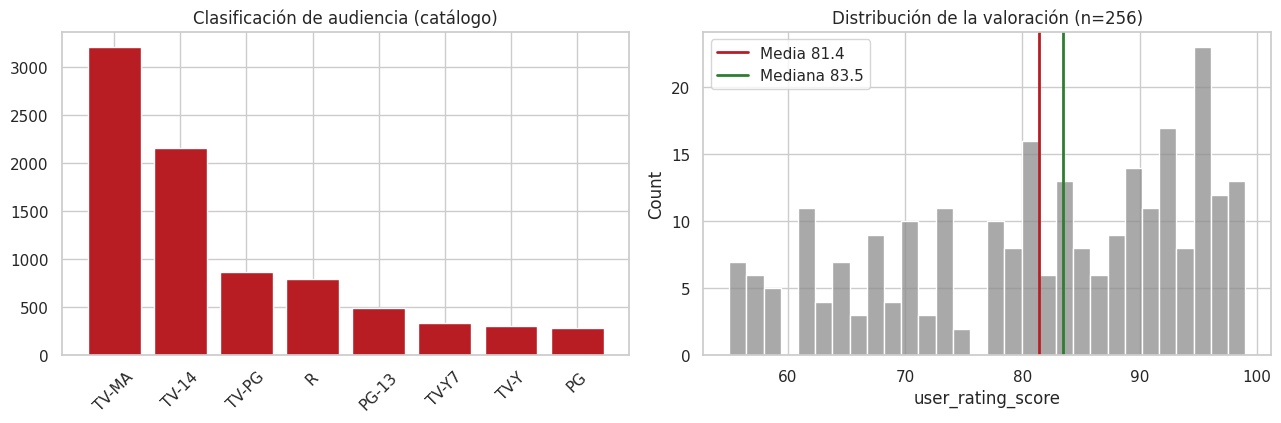

Asimetría (skew) de la valoración: -0.48


In [12]:
cl = catalogo.rating.value_counts().head(8)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].bar(cl.index, cl.values, color=ROJO); axs[0].set_title('Clasificación de audiencia (catálogo)'); axs[0].tick_params(axis='x', rotation=45)
sns.histplot(val.user_rating_score, bins=30, color=GRIS, ax=axs[1]); axs[1].axvline(val.user_rating_score.mean(), color=ROJO, lw=2, label=f'Media {val.user_rating_score.mean():.1f}'); axs[1].axvline(val.user_rating_score.median(), color='#2E7D32', lw=2, label=f'Mediana {val.user_rating_score.median():.1f}')
axs[1].set_title('Distribución de la valoración (n=256)'); axs[1].legend()
guardar('g5_clasif_valoracion'); print('Asimetría (skew) de la valoración:', round(stats.skew(val.user_rating_score),2))

**Interpretación.** TV-MA (3.207) y TV-14 (2.160) suman más del 60% del catálogo: predomina contenido para adolescentes y adultos (barras ordenadas por frecuencia). En la valoración, la media (81,4, línea roja) queda a la izquierda de la mediana (83,5, línea verde): asimetría negativa (≈ −0,48) con una cola hacia puntajes bajos (55–70). La mayor parte del contenido valorado gusta y una minoría queda claramente por debajo.

## 4. Análisis bivariado y multivariado

### 4.1 Heatmap de correlaciones (Pearson)

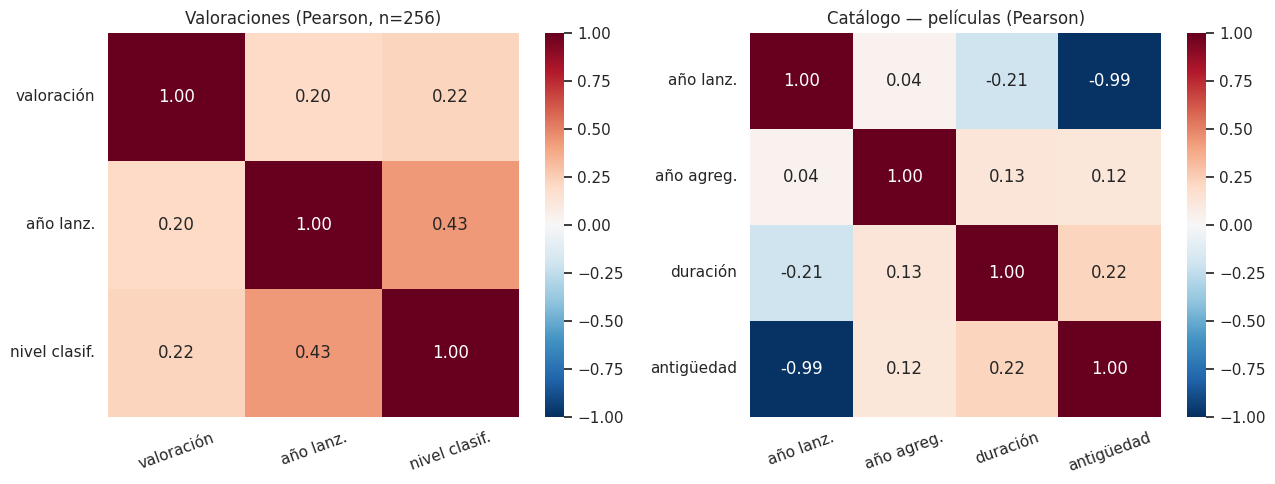

Robustez — Spearman (valoraciones):


,valoración,año lanz.,nivel clasif.
valoración,1.00,0.25,0.22
año lanz.,0.25,1.00,0.51
nivel clasif.,0.22,0.51,1.00


In [13]:
cols_val = {'user_rating_score':'valoración','release_year':'año lanz.','rating_level':'nivel clasif.'}
cols_cat = {'release_year':'año lanz.','added_year':'año agreg.','durationValue':'duración','antiguedad_al_agregar':'antigüedad'}
corr_val = val[list(cols_val)].corr(method='pearson').rename(index=cols_val, columns=cols_val)
cat_p = catalogo[catalogo.type=='Movie'][list(cols_cat)].dropna()
corr_cat = cat_p.corr(method='pearson').rename(index=cols_cat, columns=cols_cat)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(corr_val, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axs[0]); axs[0].set_title('Valoraciones (Pearson, n=256)')
sns.heatmap(corr_cat, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axs[1]); axs[1].set_title('Catálogo — películas (Pearson)')
for ax in axs: ax.tick_params(axis='y', rotation=0); ax.tick_params(axis='x', rotation=20); ax.grid(False)
guardar('g6_heatmap_corr')
print('Robustez — Spearman (valoraciones):'); display(val[list(cols_val)].corr(method='spearman').round(2).rename(index=cols_val, columns=cols_val))

**Interpretación.** Rojo indica correlación positiva y azul negativa. Con la valoración las relaciones son débiles: títulos más recientes (r = 0,20) y con mayor nivel de clasificación (r = 0,22) puntúan algo mejor; entre sí, año de lanzamiento y nivel de clasificación tienen una correlación moderada (r = 0,43), sin llegar a ser redundantes. **Redundancia:** en el catálogo, `antiguedad_al_agregar` y `release_year` tienen r = −0,99, porque la antigüedad se calcula a partir del año de lanzamiento; no deben usarse juntas en un modelo lineal (multicolinealidad). La correlación de Spearman da resultados parecidos (0,25 y 0,22), por lo que la conclusión no depende del método. `user_rating_size` se excluye: solo toma 3 valores y codifica si hay puntuación (ver 2.2).

### 4.2 Matriz de dispersión

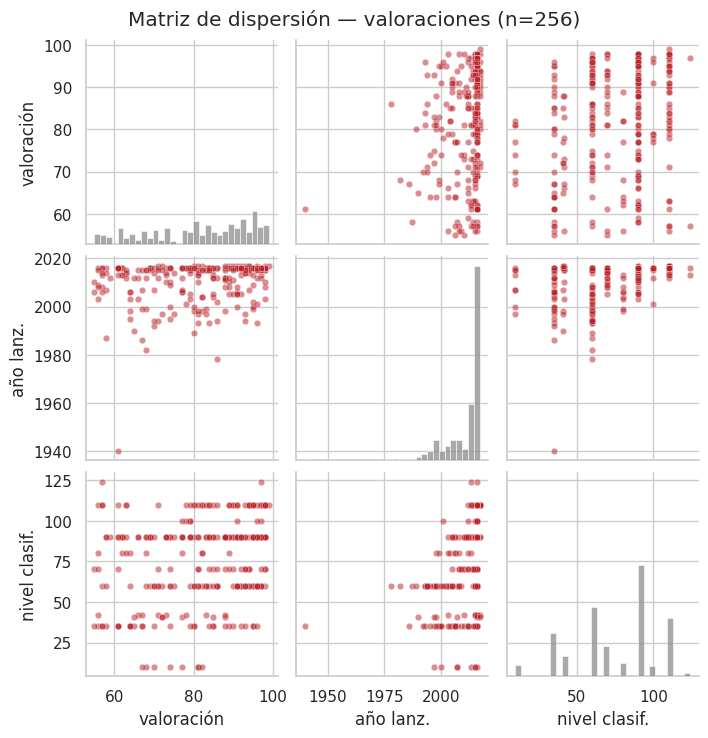

In [14]:
g = sns.pairplot(val[list(cols_val)].rename(columns=cols_val), diag_kind='hist', corner=False,
                 plot_kws={'alpha':.5, 's':22, 'color':ROJO}, diag_kws={'color':GRIS, 'bins':30}, height=2.4)
g.fig.suptitle('Matriz de dispersión — valoraciones (n=256)', y=1.02)
g.fig.savefig('figs/g6b_matriz_dispersion.png', dpi=170, bbox_inches='tight'); plt.show()

**Interpretación.** Cada fila y columna cruza dos variables y la diagonal muestra el histograma de cada una. Las nubes de puntos son anchas y sin forma clara: no hay una relación lineal fuerte con la valoración, lo que confirma las correlaciones débiles. `nivel clasif.` es discreta (los puntos forman bandas verticales) y `año lanz.` se concentra sobre todo entre 2010 y 2017, con pocos títulos antiguos. El histograma de la valoración confirma la concentración en puntajes altos.

### 4.3 Dispersión con recta de tendencia

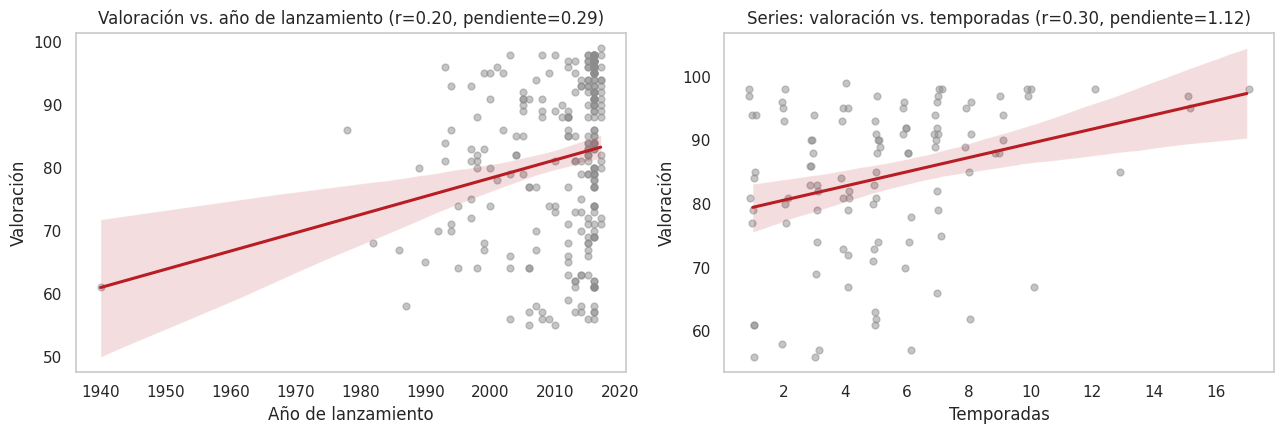

Año: r=0.20, pendiente=0.290 pts/año, p=0.0013, n=256
Temporadas (series): r=0.30, pendiente=1.12 pts/temporada, p=0.0016, n=108

Robustez de la tendencia valoración ~ año de lanzamiento:
  todos                  n=256  r=0.20  pendiente=0.29  p=0.0013
  sin el título de 1940  n=255  r=0.17  pendiente=0.29  p=0.0053
  desde 1990             n=250  r=0.15  pendiente=0.28  p=0.0216
  desde 2000             n=225  r=0.13  pendiente=0.39  p=0.0456


In [15]:
m0 = val.merge(catalogo.drop_duplicates('title')[['title','type','duration']], on='title', how='inner')
m0['temporadas'] = pd.to_numeric(m0.duration.str.split(' ').str[0], errors='coerce')
ser = m0[m0.type=='TV Show'].dropna(subset=['temporadas'])
r1 = stats.linregress(val.release_year, val.user_rating_score); r2 = stats.linregress(ser.temporadas, ser.user_rating_score)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
sns.regplot(x=val.release_year, y=val.user_rating_score, scatter_kws={'alpha':.5,'s':24,'color':GRIS}, line_kws={'color':ROJO,'lw':2.2}, ax=axs[0])
axs[0].set_title(f'Valoración vs. año de lanzamiento (r={r1.rvalue:.2f}, pendiente={r1.slope:.2f})'); axs[0].set_xlabel('Año de lanzamiento'); axs[0].set_ylabel('Valoración')
sns.regplot(x=ser.temporadas, y=ser.user_rating_score, x_jitter=.15, scatter_kws={'alpha':.5,'s':24,'color':GRIS}, line_kws={'color':ROJO,'lw':2.2}, ax=axs[1])
axs[1].set_title(f'Series: valoración vs. temporadas (r={r2.rvalue:.2f}, pendiente={r2.slope:.2f})'); axs[1].set_xlabel('Temporadas'); axs[1].set_ylabel('Valoración')
for ax in axs: ax.grid(False)
guardar('g6c_dispersion_recta')
print(f'Año: r={r1.rvalue:.2f}, pendiente={r1.slope:.3f} pts/año, p={r1.pvalue:.4f}, n={len(val)}')
print(f'Temporadas (series): r={r2.rvalue:.2f}, pendiente={r2.slope:.2f} pts/temporada, p={r2.pvalue:.4f}, n={len(ser)}')
print('\nRobustez de la tendencia valoración ~ año de lanzamiento:')
for etiqueta, d in [('todos', val), ('sin el título de 1940', val[val.release_year>1940]), ('desde 1990', val[val.release_year>=1990]), ('desde 2000', val[val.release_year>=2000])]:
    rr = stats.linregress(d.release_year, d.user_rating_score); print(f'  {etiqueta:<22} n={len(d):<4} r={rr.rvalue:.2f}  pendiente={rr.slope:.2f}  p={rr.pvalue:.4f}')

**Interpretación.** Cada punto es un título y la recta roja es el ajuste por mínimos cuadrados. Con el año de lanzamiento la relación es positiva pero débil (r = 0,20; ≈ 0,29 puntos por año, cerca de 3 por década) y la nube es muy ancha: el año explica poco. Además la recta está influida por pocos títulos antiguos (solo 6 son anteriores a 1990, uno de 1940): si se usan solo títulos desde 2000 la correlación baja a r = 0,13 (p = 0,046). En las series, cada temporada adicional se asocia con ≈ 1,1 puntos más (r = 0,30, n = 108), pero hay muy pocas series de más de 8 temporadas; probablemente se debe a que solo se renuevan las series que gustan, y no significa que alargar una serie mejore su valoración.

### 4.4 Cruce con la variable objetivo: valoración por género y por audiencia

Títulos de valoraciones que coinciden con el catálogo: 137 {'TV Show': 108, 'Movie': 29}


/tmp/ipykernel_151/2972477910.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=val, x='audiencia', y='user_rating_score', order=['Infantil/Familiar','Otra (PG, TV-PG, UR)','Adolescente/Adulto'], palette=[GRIS,NEGRO,ROJO], ax=axs[1])


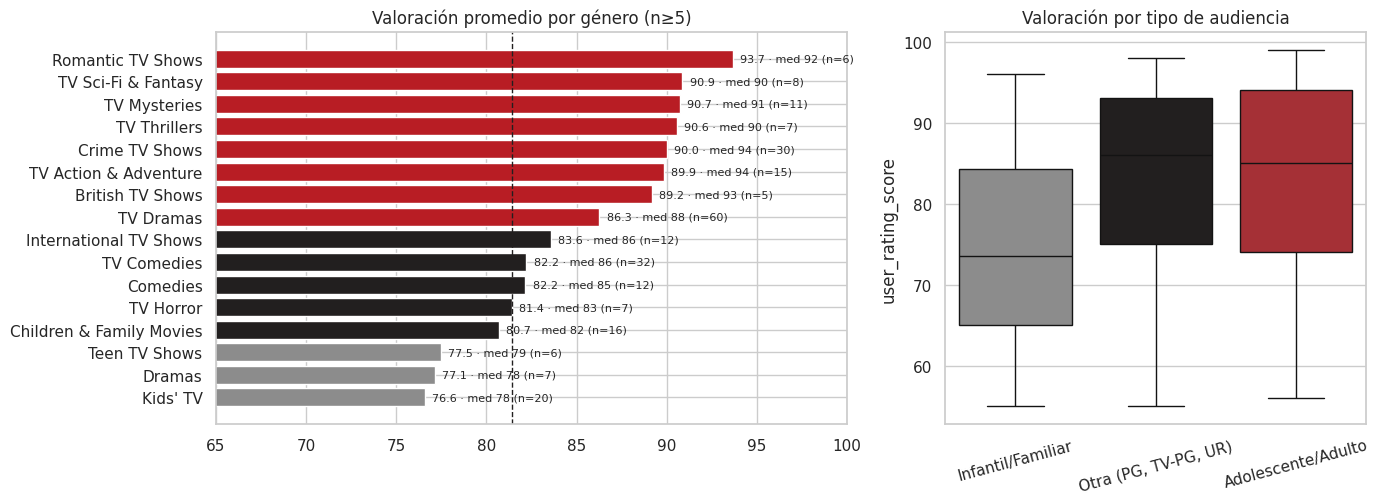

,count,mean,median
audiencia,,,
Adolescente/Adulto,135,82.7,85.0
Infantil/Familiar,52,74.5,73.5
"Otra (PG, TV-PG, UR)",69,84.0,86.0


,count,mean
type,,
Movie,29,80.8
TV Show,108,84.3


In [16]:
kids = ['TV-Y','TV-Y7','TV-Y7-FV','TV-G','G']; teen_adult = ['TV-14','TV-MA','R','PG-13','NR']
val['audiencia'] = np.where(val.rating.isin(kids), 'Infantil/Familiar', np.where(val.rating.isin(teen_adult), 'Adolescente/Adulto', 'Otra (PG, TV-PG, UR)'))
cat_u = catalogo.drop_duplicates('title')[['title','type','listed_in','duration']]
m = val.merge(cat_u, on='title', how='inner'); m['durv'] = pd.to_numeric(m.duration.str.split(' ').str[0], errors='coerce')
print('Títulos de valoraciones que coinciden con el catálogo:', len(m), m.type.value_counts().to_dict())
me = m.assign(genero=m.listed_in.str.split(', ')).explode('genero'); me['genero'] = me.genero.str.strip()
rg = me.groupby('genero').user_rating_score.agg(['count','mean','median']); rg = rg[rg['count']>=5].sort_values('mean', ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios':[1.5,1]})
cols = [ROJO if x>=85 else (NEGRO if x>=80 else GRIS) for x in rg['mean']]
axs[0].barh(rg.index[::-1], rg['mean'][::-1], color=cols[::-1]); axs[0].set_xlim(65,100)
for i,(g,r) in enumerate(rg[::-1].iterrows()): axs[0].text(r['mean']+.4, i, f"{r['mean']:.1f} · med {r['median']:.0f} (n={int(r['count'])})", va='center', fontsize=8)
axs[0].axvline(val.user_rating_score.mean(), color=NEGRO, ls='--', lw=1); axs[0].set_title('Valoración promedio por género (n≥5)')
sns.boxplot(data=val, x='audiencia', y='user_rating_score', order=['Infantil/Familiar','Otra (PG, TV-PG, UR)','Adolescente/Adulto'], palette=[GRIS,NEGRO,ROJO], ax=axs[1])
axs[1].set_title('Valoración por tipo de audiencia'); axs[1].set_xlabel(''); axs[1].tick_params(axis='x', rotation=15)
guardar('g7_valoracion_genero_audiencia')
display(val.groupby('audiencia').user_rating_score.agg(['count','mean','median']).round(1))
display(m.groupby('type').user_rating_score.agg(['count','mean']).round(1))

**Interpretación.** El contenido infantil/familiar promedia ≈ 74,5 puntos frente a ≈ 82,7 del contenido adolescente/adulto (≈ 8 puntos de diferencia). Por género, los dramas serializados de crimen, misterio, thriller, ciencia ficción y romance lideran (≈ 90–94), mientras *Kids' TV*, *Dramas* y *Teen TV Shows* quedan al fondo (≈ 77). Las series (n=108) puntúan más que las películas (n=29).

### 4.5 Multivariado — heatmap género × período de lanzamiento

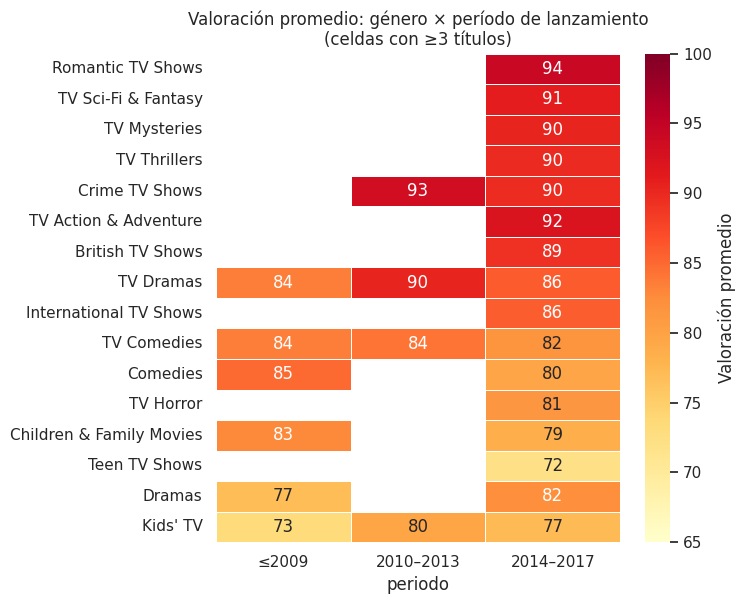

In [17]:
me['periodo'] = pd.cut(me.release_year, [1939, 2009, 2013, 2017], labels=['≤2009','2010–2013','2014–2017'])
top_g = rg.index.tolist()
piv = me[me.genero.isin(top_g)].pivot_table(index='genero', columns='periodo', values='user_rating_score', aggfunc='mean', observed=False)
cnt = me[me.genero.isin(top_g)].pivot_table(index='genero', columns='periodo', values='user_rating_score', aggfunc='count', observed=False)
piv = piv.where(cnt >= 3).loc[rg.index]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(piv, annot=True, fmt='.0f', cmap='YlOrRd', vmin=65, vmax=100, linewidths=.5, ax=ax, cbar_kws={'label':'Valoración promedio'})
ax.set_title('Valoración promedio: género × período de lanzamiento\n(celdas con ≥3 títulos)'); ax.set_ylabel(''); ax.grid(False)
guardar('g8_heatmap_genero_periodo')

**Interpretación.** La muestra se concentra en contenido reciente: la mayoría de géneros solo tiene 3 o más títulos en 2014–2017, así que solo *TV Dramas*, *TV Comedies* y *Kids' TV* permiten comparar períodos, y en ellos la variación es de pocos puntos (≈ 3 a 7). Dentro de 2014–2017 la brecha entre géneros persiste: 89–94 en romance, acción, crimen y misterio frente a 72–79 en infantil y adolescente. Es decir, el género parece pesar más que el período, aunque con esta muestra no puede comprobarse para todos los géneros; las celdas vacías (menos de 3 títulos) no se interpretan.

### 4.6 Boxplot: valoración según número de temporadas (series)

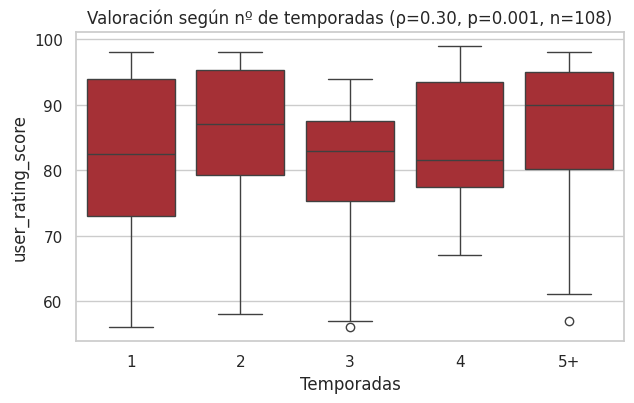

In [18]:
s = m[m.type=='TV Show'].dropna(subset=['durv'])
rho, p = stats.spearmanr(s.durv, s.user_rating_score)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.boxplot(data=s.assign(temporadas=s.durv.clip(upper=5).astype(int).astype(str).replace({'5':'5+'})), x='temporadas', y='user_rating_score', order=['1','2','3','4','5+'], color=ROJO, ax=ax)
ax.set_title(f'Valoración según nº de temporadas (ρ={rho:.2f}, p={p:.3f}, n={len(s)})'); ax.set_xlabel('Temporadas')
guardar('g9_temporadas_valoracion')

**Interpretación.** Las series con más temporadas tienden a tener mejor valoración (ρ≈0,3): es coherente con que solo las series que gustan se renuevan (efecto de supervivencia). No implica que alargar una serie mejore su valoración.

## 5. Nuevas variables e hipótesis (validación con datos)

In [19]:
# Variables nuevas: audiencia (segmento), antiguedad_al_agregar, periodo
# H1: el contenido infantil/familiar recibe menor valoración que el adolescente/adulto
a = val[val.audiencia=='Infantil/Familiar'].user_rating_score; b = val[val.audiencia=='Adolescente/Adulto'].user_rating_score
u1 = stats.mannwhitneyu(a, b, alternative='two-sided')
print(f'H1: Infantil n={len(a)} media={a.mean():.1f} | Adolescente/Adulto n={len(b)} media={b.mean():.1f} | Mann-Whitney p={u1.pvalue:.5f}')

# H2: los géneros de drama serializado puntúan más que los infantiles
alto = ['Crime TV Shows','TV Mysteries','TV Thrillers','TV Dramas','TV Sci-Fi & Fantasy','TV Action & Adventure']
bajo = ["Kids' TV",'Children & Family Movies']
hi = me[me.genero.isin(alto)].drop_duplicates('title').user_rating_score; lo = me[me.genero.isin(bajo)].drop_duplicates('title').user_rating_score
u2 = stats.mannwhitneyu(hi, lo, alternative='two-sided')
print(f'H2: Serializado n={len(hi)} media={hi.mean():.1f} | Infantil n={len(lo)} media={lo.mean():.1f} | Mann-Whitney p={u2.pvalue:.5f}')

# H3: la valoración difiere entre géneros (Kruskal-Wallis)
grupos = [g.user_rating_score.values for _, g in me[me.genero.isin(top_g)].groupby('genero')]
k = stats.kruskal(*grupos); print(f'H3: Kruskal-Wallis entre {len(grupos)} géneros: H={k.statistic:.1f}, p={k.pvalue:.5f}')

H1: Infantil n=52 media=74.5 | Adolescente/Adulto n=135 media=82.7 | Mann-Whitney p=0.00006
H2: Serializado n=75 media=86.5 | Infantil n=35 media=78.1 | Mann-Whitney p=0.00043
H3: Kruskal-Wallis entre 16 géneros: H=40.1, p=0.00045


**Resultado.** H1, H2 y H3 se **confirman** (p < 0,001): las diferencias de valoración entre audiencias y géneros no son azar. **Limitación:** la valoración solo existe para 256 títulos y apenas 137 cruzan con el catálogo por nombre (108 series y 29 películas); es una asociación, no causalidad, y no debe extrapolarse a todo el catálogo.

## 6. Hallazgos y recomendaciones (evidencia → acción)

1. **Evidencia:** el contenido infantil/familiar promedia ≈ 74,5 y el adolescente/adulto ≈ 82,7 (p < 0,001). **Acción:** revisar la oferta infantil (calidad/curaduría) o complementar con otras métricas antes de decidir inversión.
2. **Evidencia:** los géneros serializados (crimen, misterio, thriller, drama, ciencia ficción, acción) promedian ≈ 86,5 frente a ≈ 78,1 del contenido infantil. **Acción:** priorizar estos géneros al decidir qué producir o adquirir.
3. **Evidencia:** el catálogo pasó de menos de 25 títulos/año hasta 2015 a un pico de 2.016 en 2019, y baja en 2020–2021. **Acción:** pasar de crecer en volumen a medir calidad por título.
4. **Evidencia:** la mitad de `netflix.csv` eran duplicados y duplicaban el promedio (84,1 → 81,4 al limpiarlos). **Acción:** validar la fuente y automatizar la deduplicación antes de reportar métricas. Además, 88 fechas del catálogo traían un espacio inicial y se perdían al convertirlas: agregar `.str.strip()` al proceso de limpieza.

## 7. Anexo — Exportar resultados

In [20]:
os.makedirs('CSV/resultados', exist_ok=True)
catalogo.to_csv('CSV/resultados/netflix_dataset_procesado.csv', index=False)
rg.round(2).to_csv('CSV/resultados/valoracion_por_genero.csv')
print('Archivos exportados en CSV/resultados/')

Archivos exportados en CSV/resultados/
